<a href="https://colab.research.google.com/github/SarahAbuirmeileh/PyTorch_Learning/blob/03-PyTorch-Computer-Vision/notebooks/learning/03_PyTorch_Computer_Vision.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Computer Vision

**Computer vision** is the art of teaching a computer to see.

**Computer vision tasks** include methods for acquiring, processing, analyzing, and understanding digital images, and extraction of high-dimensional data from the real world in order to produce numerical or symbolic information, e.g. in the form of decisions



## 0. Computer Vision libraries in PyTorch

* `torchvision` - base domain library for pytorch computer vision
* `torchvision.datasets` - get datasets and data loading functions for computer vision
* `torchvision.models` - get pre-trained computer vision models that you can legerage for your own problems
* `torchvision.transforms` - funs for manupulating your vision data (images) to be suitable for use with ML models
* `torch.utils.data.Dataset` - Base dataset class for PyTorch  
* `torch.utils.data.Dataloader` - Create a python iterable over a dataset



In [16]:
# import libraries

import torch
import torchvision
from torchvision import datasets
from torchvision import transforms
from torchvision.transforms import ToTensor

# for visulaization
import matplotlib.pyplot as plt

# 1. Getting our dataset

We are goig to use `fashionMNIST` from `torchvision.Datasets`

In [17]:
# Seting up traning data

train_data = datasets.FashionMNIST(
    root="data", # Where to download data to
    train=True, # Do you  want a traning dataset
    download=True,
    transform=ToTensor(), # How do we want to transform the data-> torchvision.transforms.ToTensor()
    target_transform=None # How do we want to transform the lables/targets
)

# Setting up test data

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [18]:
len(train_data), len(test_data)

(60000, 10000)

In [19]:
# See the first training example

image, label = train_data[0]
image, label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [20]:
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [21]:
class_to_idx =  train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [22]:
image.shape, label.shape

AttributeError: 'int' object has no attribute 'shape'

In [27]:
type(image), type(label)

(torch.Tensor, int)

In [28]:
image.shape, label

(torch.Size([1, 28, 28]), 9)

In [29]:

# Check the shape of our image
print(f"Image shape: {image.shape} -> [color_channels, height, width]")
print(f"Image label: {class_names[label]}")

Image shape: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Image label: Ankle boot


In [30]:
# c=1 -> one color channel (black & White)

In [31]:
# Visualize our data

import matplotlib.pyplot as plt
image, label = train_data[0]
print(f"Image shape: {image.shape}")

Image shape: torch.Size([1, 28, 28])


TypeError: Invalid shape (1, 28, 28) for image data

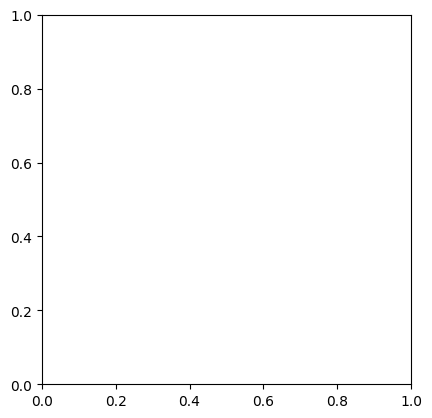

In [32]:
# visualizae the image

plt.imshow(image)

Text(0.5, 1.0, '9:Ankle boot')

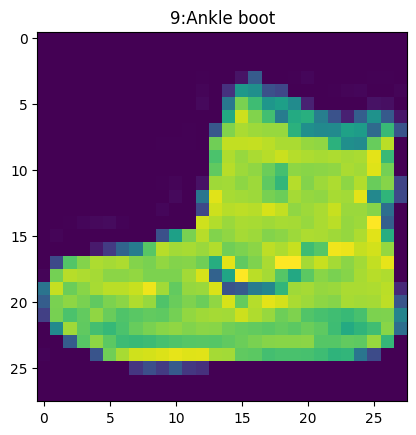

In [33]:
# plt expext (h, w, c) or without the color channel
# so we will squeeze the extra dimention

plt.imshow(image.squeeze())
# add a title to it
plt.title(f"{label}:{class_names[label]}")


(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

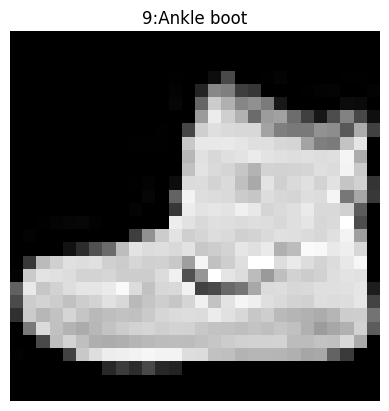

In [34]:
# pritn it gray
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"{label}:{class_names[label]}")
plt.axis(False)

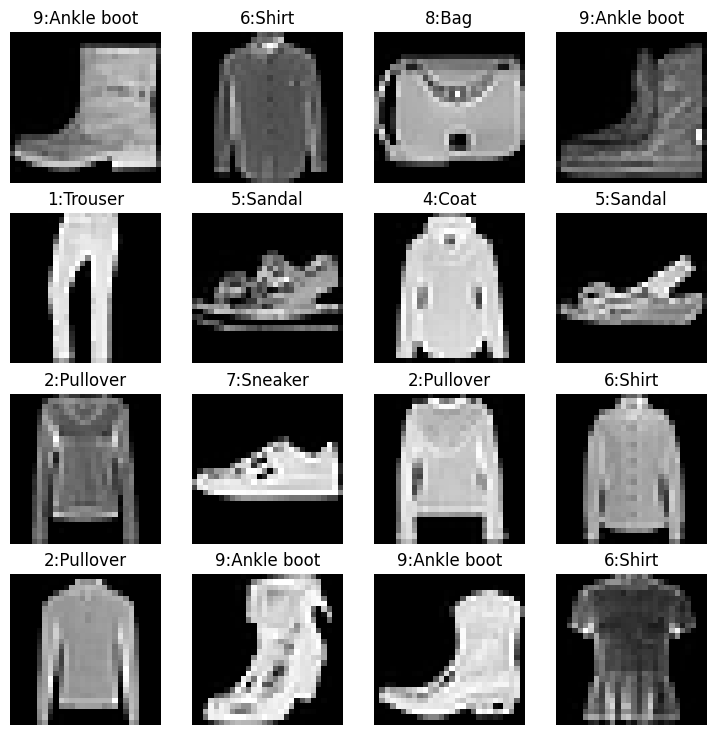

In [35]:
# plot more images

RANDOM_SEED=42

torch.manual_seed(RANDOM_SEED)
fig = plt.figure(figsize=(9, 9))
rows, cols = 4, 4 # print 16 image
for i in range(1, rows*cols +1):
  # choose random 16 image
  # size = to define the size of the output tensor
  # .item to get the value of the tensor
  random_idx = torch.randint(0, len(train_data), size=[1]).item()
  # print(random_idx)
  image, label = train_data[random_idx]
  fig.add_subplot(rows, cols, i)
  plt.imshow(image.squeeze(), cmap="gray")
  plt.title(f"{label}:{class_names[label]}")
  plt.axis(False)

### Do these data need linear lines or non-lieanrity ?

In [36]:
train_data, test_data

(Dataset FashionMNIST
     Number of datapoints: 60000
     Root location: data
     Split: Train
     StandardTransform
 Transform: ToTensor(),
 Dataset FashionMNIST
     Number of datapoints: 10000
     Root location: data
     Split: Test
     StandardTransform
 Transform: ToTensor())

## 2. Prepare our dataLoader

right now our data is in the form of pytorch dataset

`DataLoader` turn our dataset into a python iterable

more specifically, we want to turn our data into batches (or mini-batches)

** why we would to do this?**
1. it's more computaitoinlly efficint, as the computer hardware may not be able to look (store memory) at 60000 images at one hit.

So we break it down for 32 images at a time (batch size of 32)

2. It gives our nn more chances to update its greident per epoch

`if not batched` -> we have to look at 60,000 images per epoch -> get one update per epoch

`with batching` -> the nn update it's weight each 32 images

For more on mini-batches, see here: https://youtu.be/l4lSUAcvHFs

In [37]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

# Turn dataset into iterables (batches)

# shuffel to mix the data -> we might have the t-shirts ordered, we want to shake, them as we want the nn to learn the patter not the order of items

# -> to reduce model overfitting

train_dataloader = DataLoader(
  dataset=train_data,
  batch_size=BATCH_SIZE,
  shuffle=True
)

test_dataloader = DataLoader(
  dataset=test_data,
  batch_size=BATCH_SIZE,
  shuffle=False # No need to shuffle test data; we're only evaluating the model
)

train_dataloader, test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x79b87a1a9d30>,
 <torch.utils.data.dataloader.DataLoader at 0x79b8788460d0>)

In [38]:
# Check out what we've created

print(f"Dataloaders: {train_dataloader, test_dataloader}")
print(f"length of the train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"length of the test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")


Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x79b87a1a9d30>, <torch.utils.data.dataloader.DataLoader object at 0x79b8788460d0>)
length of the train dataloader: 1875 batches of 32
length of the test dataloader: 313 batches of 32


In [39]:
# Check out what's inside the traning dataloader

# iter -> transform the dataloader into a python iteratorable -> so we can loop through it
# next -> fitches the first item of that iterable

train_features_batch, train_labels_batch = next(iter(train_dataloader))
train_features_batch.shape, train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

image size: torch.Size([1, 28, 28])
label: 6, label size: torch.Size([])


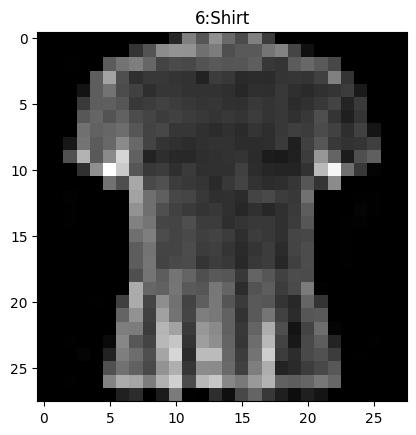

In [40]:
# show a random sample of a patch

torch.manual_seed(RANDOM_SEED)
random_idx = torch.randint(0, len(train_features_batch), size=[1]).item()

img, label = train_features_batch[random_idx], train_labels_batch[random_idx]

plt.imshow(image.squeeze(), cmap="gray")
# print(f"label:{label}")
plt.title(f"{label}:{class_names[label]}")

print(f"image size: {img.shape}")
print(f"label: {label}, label size: {label.shape}")

## 3. Build a baseline model

When starting to build a series of machine learning modelling experiments, it's best practice to start with a baseline model

**A baseline model** is a simple model you will try and improve upon  with subsequesnt modela/experiments

`Start simple then add compleixity when necessery

In [41]:
# Create a flatter layer
import torch.nn as nn
flatten_layer = nn.Flatten()

# Get a single sample
x = train_features_batch[0]
# y = train_labels_batch[0]
x.shape, x

# Flatten the sample
output = flatten_layer(x) # perform forward pass
# output.shape, output

print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {output.shape} ->[color_channels, height*width]")

# Why?
# B. we are trying to convert our data into vector sapce (n-dim)

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) ->[color_channels, height*width]


In [42]:
class FashionMNISTModelV0(nn.Module):
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int ):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.Linear(in_features=hidden_units, out_features=output_shape),

    )

  def forward(self, x):
    return self.layer_stack(x)

In [43]:
[color_channels, height, width] = image.shape
color_channels, height, width

(1, 28, 28)

In [44]:
torch.manual_seed(RANDOM_SEED)
model_0 = FashionMNISTModelV0(
    input_shape=height*width,
    hidden_units=10,
    output_shape=len(class_names)
).to("cpu")
model_0

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [45]:
# dummy input x to test our model
dummy_x=torch.rand([1, 1, 28, 28])
model_0(dummy_x).shape # 10-> the number of output classes

torch.Size([1, 10])

In [46]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

### 3.1 Set up loss fun, optmizer and evlauation matric

1. `loss fun` -> CrossEntropyLoss -> b. we have multi-class classification
2. `optimizer` -> SGD -> as stohastice greaident descnt
3. `Evaluation Metric` -> since we are wotking with calssification probelm -> `accuracy`

** Accuracy we have 3 options: **
1. Write the code ourself -> it's easy as shown bellow
2. download from helper fun. file
3. **Use the built-in function in torchmetrics**

**1.**
```
# Calculate accuracy (a classification metric)
def accuracy_fn(y_true, y_pred):

    correct = torch.eq(y_true, y_pred).sum().item()
    # torch.eq() calculates where two tensors are equal
    
    acc = (correct / len(y_pred)) * 100

    return acc

```

**2.**
```
import requests
from pathlib import Path

# Download helper functions from Learn PyTorch repo (if not already downloaded)

if Path("helper_functions.py").is_file():
  print("helper_functions.py already exists, skipping download")
else:
  print("Downloading helper_functions.py")
  # Note: you need the "raw" GitHub URL for this to work
  request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
  with open("helper_functions.py", "wb") as f:
    f.write(request.content)
```

In [47]:
# 3. use from torchmetrics
! pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 33.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchmetrics]


In [48]:
from torchmetrics import Accuracy

accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names))

In [49]:
# set up loss fin and optimizer
import torch.optim as optim

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_0.parameters(),
                      lr = 0.1)

### 3.2 create a function to time our experiminets

ML is very expirimental

Two things you'll often want to track are:
1. Model's performance **(loss & accuracy)**
2. How fast it runs

In [50]:
from timeit import default_timer as timer

def print_train_time(start:float,
                     end: float,
                     device:torch.device = None):
  total_time = end - start
  print(f"Train time on {device}: {total_time:.3f} seconds")
  return total_time

In [51]:
# example usage

start = timer()
# Some code ...
end = timer()
print_train_time(start, end, device="cpu")

Train time on cpu: 0.000 seconds


7.656500002894973e-05

### 3.3 train the model on batches of data

The optimizer will update model's parameter once per patch not per epoch

### 3.3 create a training loop and train the model on patches of data

1. loop through epochs
2. loop through traning batches, perform training steps, calc train **loss per batch**
3. loop through testing batches, perform testing steps, calc **test loss per batch**
4. print put what is happening.
5. Time it all   

In [52]:
# import tqdm for progress bar
from tqdm.auto import tqdm

# Set the seed and start the timer
torch.manual_seed(RANDOM_SEED)
train_time_start_on_cpu = timer()

# Set epochs (small for faster computations)
epochs = 3

# create traning and testing loops
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch} \n-----")

  # training
  train_loss = 0 # to accumalete loss per batch

  # add a loop to loop through our training batches
  # After each batch our model is getting slightly better
  for batch, (X, y) in enumerate(train_dataloader):
    # why we add enamurate?
    # to
    model_0.train()

    # 1. forward pass
    y_preds = model_0(X)

    # 2. clac the loss (per batch)
    loss = loss_fn(y_preds, y)
    train_loss += loss # cculamete it for every batch

    # 3. optimizer zero grad
    optimizer.zero_grad()

    # 4. loss backward
    loss.backward()

    # 5. optimizer step
    optimizer.step()

    if batch % 400 == 0:
      print(f"Looked at {batch * len(X)}/{len(train_dataloader.dataset)} samples.")

    # divide total train loss by the length of the train dataloader
    train_loss /= len(train_dataloader)

  ## Testing loop
  test_loss, test_acc = 0, 0
  model_0.eval()
  with torch.inference_mode():
    for X_test, y_test in test_dataloader:
      # 1. forward pass
      test_preds = model_0(X_test)

      # 2, calc the loss accumulativly
      test_loss += loss_fn(test_preds, y_test)

      # 3. calc the accuracy
      # .argmax(dim=1) -> to get the heighest problabitliy
      test_acc += accuracy_fn(y_test, test_preds.argmax(dim=1))

    # calc the test loss & acc avg / batch
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

  print(f"\nTrain loss: {train_loss:.4f} | Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

train_time_end_on_cpu = timer()
total_train_time_model_0 = print_train_time(start=train_time_start_on_cpu,
                                            end=train_time_end_on_cpu,
                                            device=str(next(model_0.parameters()).device))

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0 
-----
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss: 0.0002 | Test loss: 0.5095, Test acc: 0.8204
Epoch: 1 
-----
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss: 0.0003 | Test loss: 0.4799, Test acc: 0.8320
Epoch: 2 
-----
Looked at 0/60000 samples.
Looked at 12800/60000 samples.
Looked at 25600/60000 samples.
Looked at 38400/60000 samples.
Looked at 51200/60000 samples.

Train loss: 0.0002 | Test loss: 0.4766, Test acc: 0.8343
Train time on cpu: 38.336 seconds


In [53]:
# 4. Make a prediction and get Model 0 results

torch.manual_seed(RANDOM_SEED)
def eval_model(model: torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:nn.Module,
               accuracy_fn):
  """Returns a dictionary containing the results of model predicting on data_loader."""

  loss, acc  = 0,0
  model.eval()
  with torch.inference_mode():
    # loop through the data loader
    for X, y in data_loader:
      # make a prediction with the model
      y_preds = model_0(X)

      # accumelate the loss and acc per batch
      loss += loss_fn(y_preds, y)
      acc += accuracy_fn(y_preds.argmax(dim=1), y)

    # scale the loss and acc to find the avg loss/acc per batch
    loss /= len(data_loader)
    acc /= len(data_loader)

  return {"model_name": model.__class__.__name__, # only works when model was created with a class
          "model_loss": loss.item(),
          "model_acc": acc}


# Calculate model 0 results on test dataset
model_0_results = eval_model(model=model_0,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn)
model_0_results


{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': tensor(0.8343)}

### 5. Setup device agnostic-code (for using a GPU if there is one)

In [54]:
device = 'cuda' if torch.cuda.is_available() else "cpu"

device

'cuda'

## 6. Build a better model with non-linearity



In [55]:
# Create a model with linear and non-linear layers

class FashionMNISTModelV1(nn.Module):
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int ):
    super().__init__()
    self.layer_stack = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=input_shape, out_features=hidden_units),
        nn.ReLU(),
        nn.Linear(in_features=hidden_units, out_features=output_shape),
        nn.ReLU()
    )

  def forward(self, x):
    return self.layer_stack(x)

In [56]:
# Create an instance of model 1
torch.manual_seed(RANDOM_SEED)
model_1 = FashionMNISTModelV1(input_shape=height*width, # this is the output of the flatten after our 28*28 image goes in
                              hidden_units=10,
                              output_shape=len(class_names)).to(device)


In [57]:
print(model_1.parameters())
# .parameters(): is a stram (data structer), we can not access the first elment by [0], so we use next() to get the first element
print(next(model_1.parameters()))

# Then we send it to he device
print(next(model_1.parameters()).device)

<generator object Module.parameters at 0x79b854a997e0>
Parameter containing:
tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
        [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
        [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
        ...,
        [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
        [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
        [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]],
       device='cuda:0', requires_grad=True)
cuda:0


### 6.1 create a loss fun and optimizer

In [58]:
loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model_1.parameters(),
                      lr=0.1)

device='cuda' if torch.cuda.is_available() else "cpu"

accuracy_fn = Accuracy(task="multiclass", num_classes=len(class_names)).to(device)

### 6.2 Functionzing traning and evaluation/testing loops  

Let's create a function for:

training loop - `train_step()`

testing loop - `test_step()`

In [59]:
def train_step(model:nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn: nn.Module,
               optimizer:torch.optim.Optimizer,
               accuracy_fn,
               device:torch.device = device):

  # Put the model into training mode
  model.train()

  train_loss, train_accuracy = 0, 0

  # Loop through training batches
  for batch, (X, y) in enumerate(dataloader):
    X, y = X.to(device), y.to(device)

    # 1. Forward pass
    y_preds = model(X)

    # 2. Calculate the loss & acc (per batch)
    loss = loss_fn(y_preds, y)
    train_loss += loss
    train_accuracy += accuracy_fn(y_preds.argmax(dim=1), y) # logits -> prediction labels

    # 3. Optimizer zero grad
    optimizer.zero_grad()

    # 4. Loss backward
    loss.backward()

    # 5. Optimizer step
    optimizer.step()

  # Divide total train loss & acc by the length of the train dataloader (AFTER the loop)
  train_loss /= len(dataloader)
  train_accuracy /= len(dataloader)

  print(f"\nTrain loss: {train_loss:.4f} | Train CC: {train_accuracy:.4f}")

In [60]:
def test_step(model:nn.Module,
               dataloader:torch.utils.data.DataLoader,
               loss_fn: nn.Module,
               optimizer:torch.optim.Optimizer,
               accuracy_fn,
               device:torch.device = device):

  model.eval()
  test_loss, test_acc = 0, 0

  with torch.inference_mode():
    for X, y in test_dataloader:

      X, y = X.to(device), y.to(device)

      # 1. forward pass
      test_preds = model(X)

      # 2, calc the loss/acc accumulativly
      test_loss += loss_fn(test_preds, y_test)
      test_acc += accuracy_fn(y_test, test_preds.argmax(dim=1))

    # Adjust matric and print out

    # calc the test loss & acc avg / batch
    test_loss /= len(test_dataloader)
    test_acc /= len(test_dataloader)

    print(f"Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%\n")

In [61]:
torch.manual_seed(RANDOM_SEED)

# Redefining the corrected test_step to fix the y_test batch size error
def test_step(model: nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: nn.Module,
              accuracy_fn,
              optimizer: torch.optim.Optimizer = None,  # optimizer is not needed in test but kept for signature compatibility
              device: torch.device = device):
  model.eval()
  test_loss, test_acc = 0, 0
  with torch.inference_mode():
    for X, y in dataloader:
      X, y = X.to(device), y.to(device)
      test_preds = model(X)
      test_loss += loss_fn(test_preds, y) # Fixed: using 'y' instead of 'y_test'
      test_acc += accuracy_fn(test_preds.argmax(dim=1), y) # Fixed: using 'y' instead of 'y_test' and aligned arguments

    test_loss /= len(dataloader)
    test_acc /= len(dataloader)
    print(f"Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%\n")

# Measure the time
from timeit import default_timer as timer
train_time_start_on_gpu = timer()

epochs = 3

# Create a training and evaluation loop using train_step(), test_step()
for epoch in tqdm(range(epochs)):
  print(f"Epoch: {epoch} \n-----")
  train_step(model=model_1,
             dataloader=train_dataloader,
             loss_fn=loss_fn,
             accuracy_fn=accuracy_fn,
             optimizer=optimizer,
             device=device)
  test_step(model=model_1,
            dataloader=test_dataloader,
            loss_fn=loss_fn,
            accuracy_fn=accuracy_fn,
            optimizer=optimizer,
            device=device)

end_train_time_end_on_gpu = timer()

total_train_time_gpu = print_train_time(start=train_time_start_on_gpu,
                                        end=end_train_time_end_on_gpu,
                                        device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 0 
-----

Train loss: 1.0920 | Train CC: 0.6134
Test loss: 0.95636 | Test acc: 0.65%

Epoch: 1 
-----

Train loss: 0.7810 | Train CC: 0.7193
Test loss: 0.72227 | Test acc: 0.74%

Epoch: 2 
-----

Train loss: 0.6703 | Train CC: 0.7594
Test loss: 0.68500 | Test acc: 0.75%

Train time on cuda: 40.425 seconds


In [62]:
!nvidia-smi

Sat Oct 24 07:08:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P0             25W /   70W |     161MiB /  15360MiB |      9%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----


> **Note:** : sometimes, depending on your data/hardware you might find that your model training is faster on CPU rather than GPU
>
> Why is this?
>
> 1. It could be that the overhead for copying data/model to and from the GPU outweighs the compute benefits offered by the GPU.
> 2. The hardware you're using has a better CPU in terms compute capability than the GPU.
> 3. For more on how to make your models compute faster, see here: https://horace.io/brrr_intro.html




In [63]:
# Get model 1 resutls dictitinary

model_1_results = eval_model(model=model_1,
                             data_loader=test_dataloader,
                             loss_fn=loss_fn,
                             accuracy_fn=accuracy_fn)

model_1_results

{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.47663888335227966,
 'model_acc': tensor(0.8343, device='cuda:0')}

In [64]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888335227966,
 'model_acc': tensor(0.8343)}

## Model 2: build a Convenutioanl Neural Network (CNN)

* Are also known as `ConvNtets`
* Knonw for thier capablities in finding patters in visual data.

**See** -> https://poloclub.github.io/cnn-explainer/


In [69]:
from torch.nn.modules.pooling import MaxPool2d
from torch.nn.modules.activation import ReLU
# Create a CNN

class FashionMNISTModelV2(nn.Module):
  """
  Model architecture that replicates the TinyVGG
  model from CNN explainer website.
  """
  def __init__(self, input_shape:int, hidden_units:int, output_shape:int):
    super().__init__()

    # The block consists of mutible layers, and the CNN model may consitis of mutible blocks

    # We have 2 blocks -> to learn the patterns in the images
    # Then have output layer to classfiy the data into our 1- classes

    self.conv_block_1 = nn.Sequential(
        # Conv2d -> 2d data
        nn.Conv2d(in_channels=input_shape,
                  out_channels=hidden_units,
                  kernel_size=3, # 3*3
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units,
                  out_channels=hidden_units,
                  kernel_size=3,
                  stride=1,
                  padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2)
        )

    self.conv_block_2 = nn.Sequential(
      # Conv2d -> 2d data
      nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3, # 3*3
                stride=1,
                padding=1),
      nn.ReLU(),
      nn.Conv2d(in_channels=hidden_units,
                out_channels=hidden_units,
                kernel_size=3,
                stride=1,
                padding=1),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2)
      )

    self.classifier = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*7*7, # There is a trick to calc this
                  out_features=output_shape)
    )

  def forward(self, x):
    x = self.conv_block_1(x)
    x = self.conv_block_2(x)
    x = self.classifier(x)
    return x

In [70]:
RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
model_2 = FashionMNISTModelV2(input_shape=1, # The number of channeles in out images -> 1 here b. just wihte and black
                              hidden_units=10,
                              output_shape=len(class_names)).to(device)
#